 1. Data Exploration

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

data = pd.read_csv("Employee.csv")

#Data Exploration

data.head()
data.tail()
print("Shape:",data.shape)
data.info()

#Unique Values and Length

for col in data.columns:
    print("Column:", col)
    print("Unique values:", data[col].unique())
    print("Length:", data[col].nunique(dropna=False))

#Column Renaming


data.rename(columns={
    'Company': 'company_data',
    'Age': 'age_data',
    'Salary': 'salary_data',
    'Place': 'place_data',
    'Country': 'country_data',
    'Gender': 'gender_data'
}, inplace=True)

#Perform statistical analysis

data.describe()
data.head()
data.columns


Shape: (148, 6)
<class 'pandas.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 6 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Company  140 non-null    str    
 1   Age      130 non-null    float64
 2   Salary   124 non-null    float64
 3   Place    134 non-null    str    
 4   Country  148 non-null    str    
 5   Gender   148 non-null    int64  
dtypes: float64(2), int64(1), str(3)
memory usage: 9.4 KB
Column: Company
Unique values: <ArrowStringArray>
[                      'TCS',                   'Infosys',
                       'CTS',                         nan,
 'Tata Consultancy Services',                'Congnizant',
           'Infosys Pvt Lmt']
Length: 7, dtype: str
Length: 7
Column: Age
Unique values: [20. 30. 35. 40. 23. nan 34. 45. 18. 22. 32. 37. 50. 21. 46. 36. 26. 41.
 24. 25. 43. 19. 38. 51. 31. 44. 33. 17.  0. 54.]
Length: 30
Column: Salary
Unique values: [  nan 2300. 3000. 4000. 5000. 6000. 7000. 8000. 

Index(['company_data', 'age_data', 'salary_data', 'place_data', 'country_data',
       'gender_data'],
      dtype='str')

2. Data Cleaning

In [20]:
#To find missing values and inappropriate values.

data.isnull().sum()

data['age_data'] = data['age_data'].replace(0, np.nan)

data[data['age_data'].isnull()]


,company_data,age_data,salary_data,place_data,country_data,gender_data
5,Infosys,NaN,5000.0,Calcutta,India,0
6,TCS,NaN,6000.0,Chennai,India,1
23,Infosys,NaN,5835.0,Cochin,India,0
24,TCS,NaN,7084.0,Chennai,India,1
41,Infosys,NaN,5000.0,NaN,India,0
42,TCS,NaN,6000.0,NaN,India,0
59,Infosys,NaN,5835.0,Mumbai,India,0
60,TCS,NaN,7084.0,Calcutta,India,0
77,Infosys,NaN,5000.0,Hyderabad,India,0
78,TCS,NaN,6000.0,Calcutta,India,0


In [ ]:
#Remove duplicate rows

data.duplicated().sum()

data.drop_duplicates(inplace=True)

data.duplicated().sum()

In [25]:
#Find outliers

for col in ['age_data', 'salary_data']:

    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = data[
        (data[col] < lower) |
        (data[col] > upper)
    ]

    print("Column:", col)
    print("Number of outliers:", len(outliers))

 


Column: age_data
Number of outliers: 0
Column: salary_data
Number of outliers: 0


In [28]:
data['age_data'] = data['age_data'].fillna(data['age_data'].median())

data['salary_data'] = data['salary_data'].fillna(data['salary_data'].median())

data['company_data'] = data['company_data'].fillna(data['company_data'].mode()[0])

data['place_data'] = data['place_data'].fillna(data['place_data'].mode()[0])


print(data.isnull().sum())

print("Duplicates:", data.duplicated().sum())

print("Shape:", data.shape)

data.head()

company_data    0
age_data        0
salary_data     0
place_data      0
country_data    0
gender_data     0
dtype: int64
Duplicates: 0
Shape: (144, 6)


,company_data,age_data,salary_data,place_data,country_data,gender_data
0,TCS,20.0,5000.0,Chennai,India,0
1,Infosys,30.0,5000.0,Mumbai,India,0
2,TCS,35.0,2300.0,Calcutta,India,0
3,Infosys,40.0,3000.0,Delhi,India,0
4,TCS,23.0,4000.0,Mumbai,India,0


3. Data Analysis

    company_data  age_data  salary_data place_data country_data  gender_data
21       Infosys      50.0       3184.0      Delhi        India            0
32       Infosys      45.0       4034.0   Calcutta        India            0
39       Infosys      41.0       3000.0     Mumbai        India            0
50       Infosys      41.0       3000.0    Chennai        India            0
57       Infosys      51.0       3184.0  Hyderabad        India            0
68       Infosys      43.0       4034.0     Mumbai        India            0
75       Infosys      44.0       3000.0     Cochin        India            0
86       Infosys      41.0       3000.0      Delhi        India            0
93       Infosys      54.0       3184.0     Mumbai        India            0
104      Infosys      44.0       4034.0      Delhi        India            0
122      Infosys      44.0       3234.0     Mumbai        India            0
129      Infosys      50.0       3184.0   Calcutta        India            0

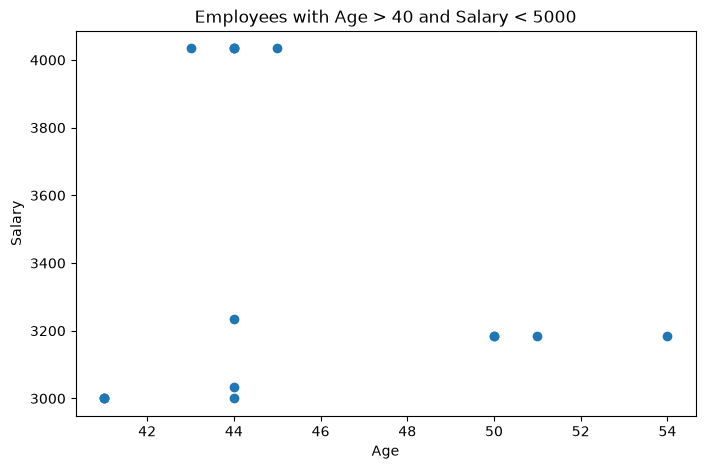

place_data
Mumbai        37
Calcutta      33
Chennai       14
Delhi         14
Cochin        13
Noida          8
Hyderabad      8
Podicherry     3
Pune           2
Bhopal         1
Nagpur         1
Name: count, dtype: int64


In [32]:
filtered_data = data[
    (data['age_data'] > 40) &
    (data['salary_data'] < 5000)
]

print(filtered_data)

print("Number of employees:", len(filtered_data))

plt.figure(figsize=(8, 5))

plt.scatter(
    filtered_data['age_data'],
    filtered_data['salary_data']
)

plt.xlabel("Age")
plt.ylabel("Salary")
plt.title("Employees with Age > 40 and Salary < 5000")

plt.show()


place_count = data['place_data'].value_counts()

print(place_count)

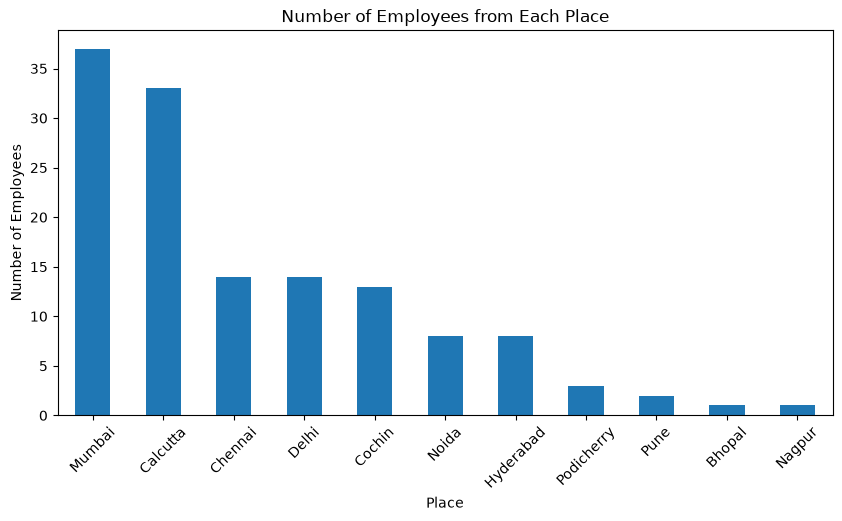

In [33]:
plt.figure(figsize=(10, 5))

place_count.plot(kind='bar')

plt.title("Number of Employees from Each Place")
plt.xlabel("Place")
plt.ylabel("Number of Employees")

plt.xticks(rotation=45)

plt.show()

 4. Data Encoding

In [43]:
#Data Encoding

from sklearn.preprocessing import LabelEncoder
company_encoder = LabelEncoder()
place_encoder = LabelEncoder()
data['company_data'] = company_encoder.fit_transform(data['company_data'])
data['place_data'] = place_encoder.fit_transform(data['place_data'])
print(data[['company_data', 'place_data']].head(10))


   company_data  place_data
0             4           2
1             2           6
2             4           1
3             2           4
4             4           6
5             2           1
6             4           2
7             2           6
8             4           1
9             0           4


In [48]:
cleaned_data = data.copy()
encoded_data = pd.get_dummies(
    cleaned_data,
    columns=['company_data', 'place_data'],
    dtype=int
)

print(encoded_data.head())

print("Original shape:", cleaned_data.shape)
print("After encoding:", encoded_data.shape)

   age_data  salary_data country_data  gender_data  company_data_0  \
0      20.0          NaN        India            0               0   
1      30.0          NaN        India            0               0   
2      35.0       2300.0        India            0               0   
3      40.0       3000.0        India            0               0   
4      23.0       4000.0        India            0               0   

   company_data_1  company_data_2  company_data_3  company_data_4  \
0               0               0               0               1   
1               0               1               0               0   
2               0               0               0               1   
3               0               1               0               0   
4               0               0               0               1   

   company_data_5  ...  place_data_2  place_data_3  place_data_4  \
0               0  ...             1             0             0   
1               0  ...      

5. Perform the scaling of the features using standardscaler and minmaxscaler.

In [57]:
#Standard scalar

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaled_data = cleaned_data.copy()

scaled_data[['age_data', 'salary_data']] = scaler.fit_transform(
    scaled_data[['age_data', 'salary_data']]
)

print("Standard Scalar:\n\n",scaled_data.head())


# Minmax Scalar

from sklearn.preprocessing import MinMaxScaler
minmax = MinMaxScaler()
minmax_data = cleaned_data.copy()

minmax_data[['age_data', 'salary_data']] = minmax.fit_transform(
    minmax_data[['age_data', 'salary_data']]
)

print("\nMinMax Scalar:\n\n",minmax_data.head())

Standard Scalar:

    company_data  age_data  salary_data  place_data country_data  gender_data
0             4 -0.948501          NaN           2        India            0
1             2 -0.043841          NaN           6        India            0
2             4  0.408489    -1.175200           1        India            0
3             2  0.860819    -0.902122           4        India            0
4             4 -0.677103    -0.512010           6        India            0

MinMax Scalar:

    company_data  age_data  salary_data  place_data country_data  gender_data
0             4  0.370370          NaN           2        India            0
1             2  0.555556          NaN           6        India            0
2             4  0.648148     0.137817           1        India            0
3             2  0.740741     0.217480           4        India            0
4             4  0.425926     0.331285           6        India            0
